# ⚡ FlashAttention Forward Pass in Triton — Branching vs. Staged Kernels

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AvinashQtC/flash-attention-triton/blob/main/flash_attention_forward_triton.ipynb)

A from-scratch **causal FlashAttention forward kernel** written in [Triton](https://triton-lang.org),
in two versions that compute the same thing but organise the causal mask differently:

| | Kernel | How the causal mask is handled |
|---|---|---|
| **V1** | `_fwd_v1_branch` | One loop over all KV tiles; a **runtime `if`** inside the loop masks tiles that touch the diagonal. Every tile pays for boundary masks. |
| **V2** | `_fwd_v2_staged` | The loop is split into **two compile-time stages** (`STAGE: tl.constexpr`): off-diagonal tiles run with **no masks at all**, only the diagonal tile is masked. No branch in the hot loop. |

Both are validated against `torch.nn.functional.scaled_dot_product_attention` (output **and** log-sum-exp)
and benchmarked on a **Colab T4 GPU** (Turing, `sm_75`).

**Contents**
1. [Setup](#1-setup)
2. [The algorithm: tiling + online softmax](#2-the-algorithm-tiling--online-softmax)
3. [A NumPy reference of the tiled algorithm](#3-a-numpy-reference-of-the-tiled-algorithm)
4. [Triton kernels](#4-triton-kernels)
5. [Correctness tests](#5-correctness-tests)
6. [Benchmark](#6-benchmark)
7. [Discussion & next steps](#7-discussion--next-steps)

> **Run it:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.

## 1. Setup

In [1]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07


In [2]:
import math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import triton
import triton.language as tl
import triton.testing

assert torch.cuda.is_available(), "Switch the Colab runtime to a GPU (T4)."
DEVICE = torch.device("cuda")
props = torch.cuda.get_device_properties(DEVICE)
print(f"GPU     : {props.name}  (sm_{props.major}{props.minor}, {props.multi_processor_count} SMs, "
      f"{props.total_memory / 2**30:.1f} GiB)")
print(f"torch   : {torch.__version__}")
print(f"triton  : {triton.__version__}")
torch.manual_seed(0)

GPU     : Tesla T4  (sm_75, 40 SMs, 14.6 GiB)
torch   : 2.11.0+cu130
triton  : 3.6.0


## 2. The algorithm: tiling + online softmax

For one (batch, head) with $Q, K, V \in \mathbb{R}^{N \times d}$, causal attention is

$$
S = \frac{QK^\top}{\sqrt{d}}, \qquad
S_{ij} \leftarrow -\infty \ \text{ if } j > i, \qquad
P = \operatorname{softmax}_{\text{row}}(S), \qquad
O = PV .
$$

The naive implementation materialises $S$ and $P$ — an $N \times N$ matrix per head — in GPU memory (HBM).
FlashAttention never does: it streams $K, V$ through on-chip SRAM in tiles and keeps a **running softmax**.

### Online softmax

Split the keys into tiles $K_1, K_2, \dots$ of width $B_{kv}$. For a block of $B_q$ query rows keep three
running quantities per row: the max $m$, the normaliser $\ell$, and the un-normalised output $\mathrm{acc}$.
For tile $j$ with scores $S_j = Q K_j^\top / \sqrt d$:

$$
\begin{aligned}
m^{\text{new}} &= \max\!\big(m,\ \operatorname{rowmax}(S_j)\big) \\
\alpha &= e^{\,m - m^{\text{new}}} &&\text{(rescales everything seen so far)}\\
\tilde P_j &= e^{\,S_j - m^{\text{new}}} \\
\ell &\leftarrow \alpha\,\ell + \operatorname{rowsum}(\tilde P_j) \\
\mathrm{acc} &\leftarrow \alpha\,\mathrm{acc} + \tilde P_j V_j \\
m &\leftarrow m^{\text{new}}
\end{aligned}
$$

The invariant after tile $j$ is $\ \mathrm{acc} = \sum_{k \le j} e^{S_k - m} V_k,\ \ \ell = \sum_{k \le j} \operatorname{rowsum}\, e^{S_k - m}$,
so at the end

$$
O = \mathrm{acc} / \ell, \qquad L = m + \log \ell = \operatorname{logsumexp}_{\text{row}}(S).
$$

$L$ is stored because the backward pass can rebuild $P = e^{S - L}$ from it without another reduction.

### Where the causal mask matters

With $B_q = B_{kv}$, query tile $i$ only needs key tiles $j \le i$:

```
            key tiles  j →
            0   1   2   3
query  0  [ D ] ·   ·   ·        F = fully visible (no mask needed)
tiles  1  [ F ][ D ] ·   ·       D = diagonal tile (causal mask needed)
  i    2  [ F ][ F ][ D ] ·      · = skipped entirely
  ↓    3  [ F ][ F ][ F ][ D ]
```

Only the $n$ diagonal tiles out of $n(n+1)/2$ computed tiles need masking — a fraction $2/(n+1)$ that shrinks
as the sequence grows. **V2 exploits this**; V1 checks every tile at runtime.

Number of computed tiles vs. tiles that actually need a mask (for $B_q = B_{kv} = 64$):

In [3]:
BLOCK = 64
rows = []
for N in [512, 1024, 2048, 4096, 8192]:
    n = math.ceil(N / BLOCK)
    computed = n * (n + 1) // 2
    rows.append({"SEQ_LEN": N, "tiles computed": computed, "diagonal (masked)": n,
                 "masked fraction": f"{n / computed:.1%}"})
pd.DataFrame(rows).set_index("SEQ_LEN")

,tiles computed,diagonal (masked),masked fraction
SEQ_LEN,,,
512,36,8,22.2%
1024,136,16,11.8%
2048,528,32,6.1%
4096,2080,64,3.1%
8192,8256,128,1.6%


## 3. A NumPy reference of the tiled algorithm

Before writing a GPU kernel, the same loop structure in plain NumPy — one query tile at a time, the two
stages of V2 made explicit. It runs on CPU and is checked against the naive $N \times N$ formula.

In [4]:
def attention_naive_np(q, k, v):
    """q, k, v: [N, d]. Materialises the full N x N score matrix."""
    N, d = q.shape
    s = q @ k.T / np.sqrt(d)
    s[np.triu_indices(N, k=1)] = -np.inf
    p = np.exp(s - s.max(axis=1, keepdims=True))
    return (p / p.sum(axis=1, keepdims=True)) @ v


def attention_tiled_np(q, k, v, block_q=64, block_kv=32):
    """Causal FlashAttention forward, written exactly like the V2 kernel."""
    N, d = q.shape
    assert block_q % block_kv == 0
    scale = 1.0 / np.sqrt(d)
    out, lse = np.empty_like(q), np.empty(N)

    for q_start in range(0, N, block_q):                     # one Triton program per query tile
        rows = np.arange(q_start, min(q_start + block_q, N))
        qi = q[rows]
        m = np.full(len(rows), -np.inf)
        l = np.zeros(len(rows))
        acc = np.zeros((len(rows), d))

        for stage in (1, 2):
            lo, hi = (0, q_start) if stage == 1 else (q_start, q_start + block_q)
            for kv_start in range(lo, min(hi, N), block_kv):
                cols = np.arange(kv_start, min(kv_start + block_kv, N))
                s = qi @ k[cols].T * scale
                if stage == 2:                                 # diagonal tile only
                    s = np.where(cols[None, :] <= rows[:, None], s, -np.inf)
                m_new = np.maximum(m, s.max(axis=1))
                p = np.exp(s - m_new[:, None])
                alpha = np.exp(m - m_new)
                l = alpha * l + p.sum(axis=1)
                acc = alpha[:, None] * acc + p @ v[cols]
                m = m_new

        out[rows] = acc / l[:, None]
        lse[rows] = m + np.log(l)
    return out, lse


rng = np.random.default_rng(0)
for N in [64, 200, 333]:
    q, k, v = (rng.standard_normal((N, 32)) for _ in range(3))
    o_tiled, _ = attention_tiled_np(q, k, v)
    print(f"N={N:4d}  max|tiled - naive| = {np.abs(o_tiled - attention_naive_np(q, k, v)).max():.2e}")

N=  64  max|tiled - naive| = 5.55e-16
N= 200  max|tiled - naive| = 7.77e-16
N= 333  max|tiled - naive| = 5.55e-16


## 4. Triton kernels

**Launch grid:** `(cdiv(SEQ_LEN, BLOCK_Q), BATCH * NUM_HEAD)` — each program owns one query tile of one head.

**Layout:** tensors are `[BATCH, NUM_HEAD, SEQ_LEN, HEAD_DIM]`. Pointer offsets use all four strides, so
non-contiguous inputs (e.g. a `[B, S, H, D]` tensor viewed with `.transpose(1, 2)`) work without a copy.

### 4.1 Autotuning space

In [5]:
# Tile configurations tried by the autotuner.
# Constraint: BLOCK_Q % BLOCK_KV == 0, so the diagonal stage of V2 starts on a KV-tile boundary.
# Configs that do not fit in T4 shared memory (64 KB/SM) are skipped automatically by the autotuner.
AUTOTUNE_CONFIGS = [
    triton.Config({"BLOCK_Q": 64,  "BLOCK_KV": 32},  num_warps=4, num_stages=2),
    triton.Config({"BLOCK_Q": 64,  "BLOCK_KV": 64},  num_warps=4, num_stages=2),
    triton.Config({"BLOCK_Q": 128, "BLOCK_KV": 64},  num_warps=4, num_stages=2),
    triton.Config({"BLOCK_Q": 128, "BLOCK_KV": 64},  num_warps=8, num_stages=3),
    triton.Config({"BLOCK_Q": 128, "BLOCK_KV": 128}, num_warps=8, num_stages=3),
]
AUTOTUNE_KEY = ["SEQ_LEN", "HEAD_DIM"]

### 4.2 V1 — single loop with a runtime branch

The loop runs over every KV tile up to the end of the query tile. Inside it, a **data-dependent `if`** decides
whether the tile crosses the diagonal. Because `start_kv` and `q_start` are runtime values, the compiler keeps
the branch in the loop body, and every tile still does boundary-masked loads and a `tl.where` on the scores.

In [6]:
@triton.autotune(configs=AUTOTUNE_CONFIGS, key=AUTOTUNE_KEY)
@triton.jit
def _fwd_v1_branch(
    Q_ptr, K_ptr, V_ptr, O_ptr, L_ptr,
    softmax_scale,
    NUM_HEAD, SEQ_LEN,
    stride_b, stride_h, stride_s, stride_d,
    HEAD_DIM: tl.constexpr, BLOCK_Q: tl.constexpr, BLOCK_KV: tl.constexpr,
):
    """V1 — one loop over all KV tiles up to the diagonal, with a *runtime* `if`
    that applies the causal mask only on tiles that touch the diagonal.
    Every tile also pays for boundary masks on its loads and scores."""
    # ---- program ids: (query tile, batch*head) -----------------------------
    pid_q  = tl.program_id(0)
    pid_bh = tl.program_id(1)
    b, h   = pid_bh // NUM_HEAD, pid_bh % NUM_HEAD
    base   = b * stride_b + h * stride_h            # stride-aware (no contiguity assumption)

    offs_q  = pid_q * BLOCK_Q + tl.arange(0, BLOCK_Q)
    offs_kv = tl.arange(0, BLOCK_KV)
    offs_d  = tl.arange(0, HEAD_DIM)

    # ---- load the Q tile once: [BLOCK_Q, HEAD_DIM] ---------------------------
    q_mask = offs_q[:, None] < SEQ_LEN
    q = tl.load(Q_ptr + base + offs_q[:, None] * stride_s + offs_d[None, :] * stride_d,
                mask=q_mask, other=0.0)

    # ---- online-softmax state ----------------------------------------------------
    m   = tl.full((BLOCK_Q,), float("-inf"), dtype=tl.float32)   # running row max
    l   = tl.zeros((BLOCK_Q,), dtype=tl.float32)                 # running row sum
    acc = tl.zeros((BLOCK_Q, HEAD_DIM), dtype=tl.float32)        # unnormalised output

    q_start = pid_q * BLOCK_Q
    q_end   = q_start + BLOCK_Q
    for start_kv in range(0, q_end, BLOCK_KV):
        kv_pos = start_kv + offs_kv

        # K^T tile [HEAD_DIM, BLOCK_KV] and V tile [BLOCK_KV, HEAD_DIM]
        kT = tl.load(K_ptr + base + kv_pos[None, :] * stride_s + offs_d[:, None] * stride_d,
                     mask=kv_pos[None, :] < SEQ_LEN, other=0.0)
        v  = tl.load(V_ptr + base + kv_pos[:, None] * stride_s + offs_d[None, :] * stride_d,
                     mask=kv_pos[:, None] < SEQ_LEN, other=0.0)

        s = tl.dot(q, kT) * softmax_scale                          # [BLOCK_Q, BLOCK_KV]

        # runtime branch: only tiles crossing the diagonal need the causal mask
        if start_kv + BLOCK_KV - 1 > q_start:
            s = tl.where(kv_pos[None, :] > offs_q[:, None], -1.0e6, s)
        # boundary mask (padded keys get ~zero weight) — applied on every tile
        s = tl.where(kv_pos[None, :] < SEQ_LEN, s, -1.0e6)

        # online softmax update
        m_new = tl.maximum(m, tl.max(s, axis=1))
        p     = tl.exp(s - m_new[:, None])
        alpha = tl.exp(m - m_new)
        l     = alpha * l + tl.sum(p, axis=1)
        acc   = acc * alpha[:, None] + tl.dot(p.to(v.dtype), v)
        m     = m_new

    # ---- epilogue -------------------------------------------------------------------
    acc = acc / l[:, None]
    tl.store(L_ptr + pid_bh * SEQ_LEN + offs_q, m + tl.log(l), mask=offs_q < SEQ_LEN)
    tl.store(O_ptr + base + offs_q[:, None] * stride_s + offs_d[None, :] * stride_d,
             acc.to(O_ptr.dtype.element_ty), mask=q_mask)

### 4.3 V2 — two compile-time stages, no branch in the hot loop

The KV sweep moves into a helper `_attn_inner(..., STAGE)`. `STAGE` is a `tl.constexpr`, so Triton compiles
**two specialised loops**:

* **Stage 1** — tiles `[0, q_start)`. Every key is `< q_start < SEQ_LEN`, so the tile is in-bounds and fully
  visible: plain unmasked loads, no `tl.where`.
* **Stage 2** — the single diagonal tile `[q_start, q_start + BLOCK_Q)`: one combined causal + boundary mask.

The running state `(acc, l, m)` is passed in and returned, and normalisation `acc / l` happens **once**, in the
caller, after both stages.

In [7]:
@triton.jit
def _attn_inner(
    acc, l, m, q,
    K_ptr, V_ptr, base, offs_q, offs_kv, offs_d,
    q_start, softmax_scale, SEQ_LEN, stride_s, stride_d,
    BLOCK_Q: tl.constexpr, BLOCK_KV: tl.constexpr, STAGE: tl.constexpr,
):
    """Process a range of KV tiles and return the updated (acc, l, m).

    STAGE == 1 : off-diagonal tiles  [0, q_start)              -> fully visible, NO masks at all
    STAGE == 2 : diagonal tiles      [q_start, q_start+BLOCK_Q) -> causal + boundary masks

    STAGE is a tl.constexpr, so each call compiles to a specialised, branch-free loop.
    """
    if STAGE == 1:
        lo, hi = 0, q_start
    else:
        lo, hi = q_start, q_start + BLOCK_Q

    for start_kv in range(lo, hi, BLOCK_KV):
        kv_pos = start_kv + offs_kv
        k_ptrs = K_ptr + base + kv_pos[None, :] * stride_s + offs_d[:, None] * stride_d
        v_ptrs = V_ptr + base + kv_pos[:, None] * stride_s + offs_d[None, :] * stride_d

        if STAGE == 1:
            # kv_pos < q_start < SEQ_LEN  ->  in bounds and causally visible
            kT = tl.load(k_ptrs)
            v  = tl.load(v_ptrs)
            s  = tl.dot(q, kT) * softmax_scale
        else:
            kT = tl.load(k_ptrs, mask=kv_pos[None, :] < SEQ_LEN, other=0.0)
            v  = tl.load(v_ptrs, mask=kv_pos[:, None] < SEQ_LEN, other=0.0)
            s  = tl.dot(q, kT) * softmax_scale
            visible = (kv_pos[None, :] <= offs_q[:, None]) & (kv_pos[None, :] < SEQ_LEN)
            s = tl.where(visible, s, -1.0e6)

        m_new = tl.maximum(m, tl.max(s, axis=1))
        p     = tl.exp(s - m_new[:, None])
        alpha = tl.exp(m - m_new)
        l     = alpha * l + tl.sum(p, axis=1)
        acc   = acc * alpha[:, None] + tl.dot(p.to(v.dtype), v)
        m     = m_new

    return acc, l, m


@triton.autotune(configs=AUTOTUNE_CONFIGS, key=AUTOTUNE_KEY)
@triton.jit
def _fwd_v2_staged(
    Q_ptr, K_ptr, V_ptr, O_ptr, L_ptr,
    softmax_scale,
    NUM_HEAD, SEQ_LEN,
    stride_b, stride_h, stride_s, stride_d,
    HEAD_DIM: tl.constexpr, BLOCK_Q: tl.constexpr, BLOCK_KV: tl.constexpr,
):
    """V2 — the KV sweep is split into two compile-time stages, so there is no
    `if` inside the hot loop and off-diagonal tiles skip all masking."""
    pid_q  = tl.program_id(0)
    pid_bh = tl.program_id(1)
    b, h   = pid_bh // NUM_HEAD, pid_bh % NUM_HEAD
    base   = b * stride_b + h * stride_h

    offs_q  = pid_q * BLOCK_Q + tl.arange(0, BLOCK_Q)
    offs_kv = tl.arange(0, BLOCK_KV)
    offs_d  = tl.arange(0, HEAD_DIM)

    q_mask = offs_q[:, None] < SEQ_LEN
    q = tl.load(Q_ptr + base + offs_q[:, None] * stride_s + offs_d[None, :] * stride_d,
                mask=q_mask, other=0.0)

    m   = tl.full((BLOCK_Q,), float("-inf"), dtype=tl.float32)
    l   = tl.zeros((BLOCK_Q,), dtype=tl.float32)
    acc = tl.zeros((BLOCK_Q, HEAD_DIM), dtype=tl.float32)
    q_start = pid_q * BLOCK_Q

    # stage 1: everything strictly left of the diagonal block
    acc, l, m = _attn_inner(acc, l, m, q, K_ptr, V_ptr, base, offs_q, offs_kv, offs_d,
                            q_start, softmax_scale, SEQ_LEN, stride_s, stride_d,
                            BLOCK_Q, BLOCK_KV, 1)
    # stage 2: the diagonal block itself
    acc, l, m = _attn_inner(acc, l, m, q, K_ptr, V_ptr, base, offs_q, offs_kv, offs_d,
                            q_start, softmax_scale, SEQ_LEN, stride_s, stride_d,
                            BLOCK_Q, BLOCK_KV, 2)

    acc = acc / l[:, None]
    tl.store(L_ptr + pid_bh * SEQ_LEN + offs_q, m + tl.log(l), mask=offs_q < SEQ_LEN)
    tl.store(O_ptr + base + offs_q[:, None] * stride_s + offs_d[None, :] * stride_d,
             acc.to(O_ptr.dtype.element_ty), mask=q_mask)

### 4.4 Python launcher

In [8]:
KERNELS = {"v1_branch": _fwd_v1_branch, "v2_staged": _fwd_v2_staged}

def flash_attention_fwd(q, k, v, version="v2_staged", return_lse=False):
    """Causal FlashAttention forward.  q, k, v: [BATCH, NUM_HEAD, SEQ_LEN, HEAD_DIM].

    Returns O (same shape/dtype as q) and optionally the log-sum-exp L [B, H, S] in fp32,
    which is what a backward pass would need.
    """
    assert q.shape == k.shape == v.shape, "self-attention only: q, k, v must share a shape"
    B, H, S, D = q.shape
    assert D in (16, 32, 64, 128), "HEAD_DIM must be a power of two in [16, 128]"
    if not (q.stride() == k.stride() == v.stride()):
        q, k, v = q.contiguous(), k.contiguous(), v.contiguous()

    o   = torch.empty_like(q)
    lse = torch.empty((B, H, S), device=q.device, dtype=torch.float32)
    grid = lambda meta: (triton.cdiv(S, meta["BLOCK_Q"]), B * H)

    KERNELS[version][grid](
        q, k, v, o, lse,
        1.0 / D ** 0.5,
        H, S,
        *q.stride(),
        HEAD_DIM=D,
    )
    return (o, lse) if return_lse else o

Quick smoke test:

In [9]:
q = torch.randn(2, 4, 256, 64, device=DEVICE, dtype=torch.float16)
k, v = torch.randn_like(q), torch.randn_like(q)
ref = F.scaled_dot_product_attention(q, k, v, is_causal=True)
for ver in KERNELS:
    out = flash_attention_fwd(q, k, v, version=ver)
    print(f"{ver:10s} max|Δ| = {(out - ref).abs().max().item():.2e}")

v1_branch  max|Δ| = 4.88e-04
v2_staged  max|Δ| = 4.88e-04


## 5. Correctness tests

Each case checks the output $O$ against PyTorch SDPA and the log-sum-exp $L$ against
`torch.logsumexp` of the explicitly masked score matrix (computed in fp32). The shapes include sequence
lengths that are **not multiples of any block size** (77, 300, 1000) and a non-contiguous input layout.

In [10]:
def reference_lse(q, k):
    S, D = q.shape[-2], q.shape[-1]
    s = (q.float() @ k.float().transpose(-1, -2)) / math.sqrt(D)
    s = s.masked_fill(torch.ones(S, S, device=q.device, dtype=torch.bool).triu(1), float("-inf"))
    return torch.logsumexp(s, dim=-1)


def check(B, H, S, D, dtype, layout="BHSD"):
    if layout == "BHSD":
        q, k, v = (torch.randn(B, H, S, D, device=DEVICE, dtype=dtype) for _ in range(3))
    else:  # BSHD storage, viewed as BHSD -> non-contiguous strides
        q, k, v = (torch.randn(B, S, H, D, device=DEVICE, dtype=dtype).transpose(1, 2) for _ in range(3))
    ref_o = F.scaled_dot_product_attention(q, k, v, is_causal=True).float()
    ref_l = reference_lse(q, k)
    tol = 1e-2 if dtype == torch.float16 else 1e-3
    rows = []
    for ver in KERNELS:
        o, lse = flash_attention_fwd(q, k, v, version=ver, return_lse=True)
        err_o = (o.float() - ref_o).abs().max().item()
        err_l = (lse - ref_l).abs().max().item()
        rows.append({"version": ver, "B": B, "H": H, "S": S, "D": D,
                     "dtype": str(dtype).split(".")[-1], "layout": layout,
                     "max|ΔO|": err_o, "max|ΔL|": err_l,
                     "pass": err_o < tol and err_l < tol})
    return rows


CASES = [
    (2, 4,  256, 64, torch.float32), (1, 8,  512, 64, torch.float32), (4, 2, 128, 64, torch.float32),
    (2, 4,  300, 64, torch.float32), (1, 4, 1000, 32, torch.float32),
    (2, 4,  256, 64, torch.float16), (1, 8, 1024, 64, torch.float16), (2, 4, 300, 64, torch.float16),
    (1, 2,   77, 128, torch.float16), (2, 2, 1024, 16, torch.float16),
]
results = [r for c in CASES for r in check(*c)]
results += check(2, 4, 384, 64, torch.float16, layout="BSHD")

tests = pd.DataFrame(results)
display(tests.style.format({"max|ΔO|": "{:.1e}", "max|ΔL|": "{:.1e}"}))
assert tests["pass"].all(), "some correctness checks failed"
print(f"All {len(tests)} checks passed.")

,version,B,H,S,D,dtype,layout,max|ΔO|,max|ΔL|,pass
0,v1_branch,2,4,256,64,float32,BHSD,3.6e-07,4.8e-07,True
1,v2_staged,2,4,256,64,float32,BHSD,3.6e-07,4.8e-07,True
2,v1_branch,1,8,512,64,float32,BHSD,3.6e-07,9.5e-07,True
3,v2_staged,1,8,512,64,float32,BHSD,3.6e-07,9.5e-07,True
4,v1_branch,4,2,128,64,float32,BHSD,3.0e-07,4.8e-07,True
5,v2_staged,4,2,128,64,float32,BHSD,3.0e-07,4.8e-07,True
6,v1_branch,2,4,300,64,float32,BHSD,3.0e-07,4.8e-07,True
7,v2_staged,2,4,300,64,float32,BHSD,3.0e-07,4.8e-07,True
8,v1_branch,1,4,1000,32,float32,BHSD,3.6e-07,9.5e-07,True
9,v2_staged,1,4,1000,32,float32,BHSD,3.6e-07,9.5e-07,True


All 22 checks passed.


## 6. Benchmark

Forward pass, fp16, `BATCH=4, NUM_HEAD=16, HEAD_DIM=64`, causal. Timings use `triton.testing.do_bench`
(median over repeated runs, L2 flushed between runs). Throughput counts the useful causal FLOPs:

$$
\text{FLOPs} = \underbrace{2}_{QK^\top,\ PV} \times 2 B H N^2 d \times \underbrace{\tfrac12}_{\text{causal}} = 2BHN^2 d .
$$

Baselines: **PyTorch SDPA** (`is_causal=True`; on `sm_75` FlashAttention-2 is unavailable, so PyTorch picks its
memory-efficient kernel) and a **naive** PyTorch implementation that materialises the $N \times N$ matrix.

In [11]:
def attention_naive_torch(q, k, v):
    S, D = q.shape[-2], q.shape[-1]
    s = (q @ k.transpose(-1, -2)) / math.sqrt(D)
    s = s.masked_fill(torch.ones(S, S, device=q.device, dtype=torch.bool).triu(1), float("-inf"))
    return torch.softmax(s.float(), dim=-1).to(q.dtype) @ v


def run_benchmark(B=4, H=16, D=64, seq_lens=(512, 1024, 2048, 4096, 8192), dtype=torch.float16):
    impls = {
        "Triton V1 (branch)": lambda q, k, v: flash_attention_fwd(q, k, v, version="v1_branch"),
        "Triton V2 (staged)": lambda q, k, v: flash_attention_fwd(q, k, v, version="v2_staged"),
        "PyTorch SDPA":       lambda q, k, v: F.scaled_dot_product_attention(q, k, v, is_causal=True),
        "PyTorch naive":      attention_naive_torch,
    }
    rows = []
    for S in seq_lens:
        q, k, v = (torch.randn(B, H, S, D, device=DEVICE, dtype=dtype) for _ in range(3))
        ref = impls["PyTorch SDPA"](q, k, v)
        flops = 2 * B * H * S * S * D
        for name, fn in impls.items():
            try:
                out = fn(q, k, v)                                   # also triggers autotuning
                torch.testing.assert_close(out, ref, atol=1e-2, rtol=1e-2)
                ms = triton.testing.do_bench(lambda: fn(q, k, v), warmup=25, rep=100)
            except torch.cuda.OutOfMemoryError:
                ms = float("nan")
                torch.cuda.empty_cache()
            rows.append({"SEQ_LEN": S, "impl": name, "ms": ms, "TFLOP/s": flops / (ms * 1e-3) / 1e12})
        del q, k, v, ref
        torch.cuda.empty_cache()
    return pd.DataFrame(rows)


bench = run_benchmark()
latency = bench.pivot(index="SEQ_LEN", columns="impl", values="ms")
latency["V2 speed-up vs V1"] = latency["Triton V1 (branch)"] / latency["Triton V2 (staged)"]
latency["V2 / SDPA time"]    = latency["Triton V2 (staged)"] / latency["PyTorch SDPA"]
display(latency.style.format("{:.3f}").set_caption("Latency (ms) — lower is better"))
display(bench.pivot(index="SEQ_LEN", columns="impl", values="TFLOP/s")
             .style.format("{:.2f}").set_caption("Throughput (TFLOP/s) — higher is better"))

impl,PyTorch SDPA,PyTorch naive,Triton V1 (branch),Triton V2 (staged),V2 speed-up vs V1,V2 / SDPA time
SEQ_LEN,,,,,,
512,0.340,2.839,5.099,5.187,0.983,15.242
1024,0.690,11.238,7.836,8.061,0.972,11.682
2048,2.999,45.430,30.403,31.280,0.972,10.431
4096,12.198,187.432,123.329,128.453,0.960,10.531
8192,47.334,nan,493.455,512.808,0.962,10.834


impl,PyTorch SDPA,PyTorch naive,Triton V1 (branch),Triton V2 (staged)
SEQ_LEN,,,,
512,6.31,0.76,0.42,0.41
1024,12.45,0.76,1.10,1.07
2048,11.46,0.76,1.13,1.10
4096,11.27,0.73,1.11,1.07
8192,11.61,nan,1.11,1.07


Configs picked by the autotuner (last tuned shape):

In [12]:
for name, kern in KERNELS.items():
    cfg = kern.best_config
    print(f"{name:10s} {cfg.kwargs}  num_warps={cfg.num_warps}  num_stages={cfg.num_stages}")

v1_branch  {'BLOCK_Q': 64, 'BLOCK_KV': 32}  num_warps=4  num_stages=2
v2_staged  {'BLOCK_Q': 64, 'BLOCK_KV': 32}  num_warps=4  num_stages=2


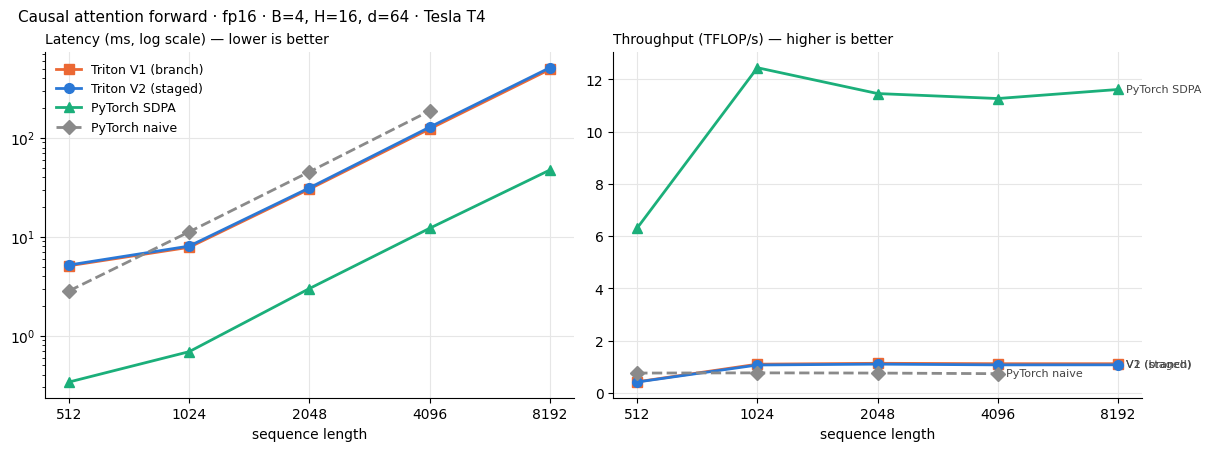

In [13]:
import os
STYLE = {  # fixed colour per implementation + distinct marker, so identity never relies on colour alone
    "Triton V1 (branch)": dict(color="#eb6834", marker="s"),
    "Triton V2 (staged)": dict(color="#2a78d6", marker="o"),
    "PyTorch SDPA":       dict(color="#1baf7a", marker="^"),
    "PyTorch naive":      dict(color="#8a8a8a", marker="D", linestyle="--"),
}

def plot_benchmark(bench, gpu_name, path="assets/benchmark_t4.png"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
    for ax, metric, title, logy in [(axes[0], "ms", "Latency (ms, log scale) — lower is better", True),
                                    (axes[1], "TFLOP/s", "Throughput (TFLOP/s) — higher is better", False)]:
        for name, st in STYLE.items():
            d = bench[bench.impl == name].dropna()
            if d.empty:
                continue
            ax.plot(d.SEQ_LEN, d[metric], label=name, linewidth=2, markersize=7, **st)
            if not logy:  # direct labels on the throughput panel; latency lines converge on log scale
                ax.annotate(name.replace("Triton ", ""), (d.SEQ_LEN.iloc[-1], d[metric].iloc[-1]),
                            xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color="#444")
        ax.set_xscale("log", base=2)
        if logy:
            ax.set_yscale("log")
        ax.set_xticks(sorted(bench.SEQ_LEN.unique()))
        ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
        ax.set_xlabel("sequence length")
        ax.set_title(title, fontsize=10, loc="left")
        ax.grid(True, which="major", color="#e6e6e6", linewidth=0.8)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    axes[0].legend(frameon=False, fontsize=9)
    fig.suptitle(f"Causal attention forward · fp16 · B=4, H=16, d=64 · {gpu_name}", fontsize=11, x=0.01, ha="left")
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

plot_benchmark(bench, props.name)
bench.to_csv("assets/benchmark_t4.csv", index=False)

## 7. Discussion & next steps

### What separates V1 and V2

| | V1 (branch) | V2 (staged) |
|---|---|---|
| Causal check | runtime `if` on every KV tile | resolved at compile time (`STAGE: tl.constexpr`) |
| Off-diagonal tiles | masked loads + boundary `tl.where` | plain loads, no masking |
| Diagonal tile | causal `tl.where` + boundary `tl.where` | one combined `tl.where` |
| Code shape | one kernel body | kernel + reusable `_attn_inner` helper |

Since only $2/(n+1)$ of the computed tiles sit on the diagonal (Section 2), V2 removes masking work from almost
every tile, and the branch-free loop gives the compiler a cleaner body to schedule. The benchmark table above
shows how much of that turns into wall-clock time on the T4.

### Notes specific to the T4 (`sm_75`)
* Turing tensor cores support fp16 `mma` but **not** `cp.async`, so `num_stages > 1` gives little software
  pipelining; configurations needing more than 64 KB shared memory are dropped by the autotuner.
* fp32 inputs run `tl.dot` on CUDA cores (no TF32 on Turing) — exact, but far slower than fp16.

### Possible next steps
- [ ] **Backward pass** — `L` is already returned, which is what the FlashAttention backward needs.
- [ ] Use `exp2` with $\log_2 e$ folded into `softmax_scale` (cheaper than `exp` on the SFU).
- [ ] Non-causal mode and variable-length (packed) sequences.
- [ ] GQA / MQA (fewer KV heads than Q heads).
- [ ] Wrap in `torch.autograd.Function` once the backward kernel exists.

### References
1. T. Dao et al., *FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness*, NeurIPS 2022. [arXiv:2205.14135](https://arxiv.org/abs/2205.14135)
2. T. Dao, *FlashAttention-2: Faster Attention with Better Parallelism and Work Partitioning*, 2023. [arXiv:2307.08691](https://arxiv.org/abs/2307.08691)
3. M. Milakov, N. Gimelshein, *Online normalizer calculation for softmax*, 2018. [arXiv:1805.02867](https://arxiv.org/abs/1805.02867)
4. Triton tutorial: [Fused Attention](https://triton-lang.org/main/getting-started/tutorials/06-fused-attention.html)